# 0. Imports

In [1]:
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    import warnings
    warnings.warn(
        "Intel(R) Extension for Scikit-learn is not installed." \
        "If using an intel CPU, consider installing it for potentially a ~10x speedup in model training and inference."
        "(pip install scikit-learn-intelex)")
    pass

import cartopy.crs as ccrs # Enables geographic mapping, e.g., drawing coastlines, etc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import shap
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split, KFold, cross_val_score, GridSearchCV, StratifiedKFold, PredefinedSplit
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, balanced_accuracy_score, f1_score, log_loss, cohen_kappa_score
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV # type: ignore

plt.rcParams.update({'font.size': 8})
try:
    plt.style.use('pgf.mplstyle')
except FileNotFoundError:
    print("pgf.mplstyle not found, using default matplotlib style.")

proj = ccrs.PlateCarree()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


# 1. Data

In [2]:
DATA_DIR = "../data/"
FIG_DIR = "../figures/"

LAT_LON = ["Lat", "Lon"]

RANDOM_SEED = 42

In [3]:
#LPJ-GUESS output
lpj_df = pl.read_csv(DATA_DIR + "LPJ-GUESS_output_BERN1.csv")
lpj_df = lpj_df.rename({col: col + f"_lpj" for col in lpj_df.columns if not col in LAT_LON})
lpj_df

Lon,Lat,NPP_lpj,SoilR_lpj,MaxBiomeCmax_lpj,MaxBiomeLAI_lpj,VegC_lpj,LitterC_lpj,SoilC_lpj,Biome_Cmax_lpj,Biome_LAI_lpj,Biome_obs_lpj
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64
39.75,-1.25,0.429,0.39,0.449,1.9821,1.225,0.758,5.941,8,12,12
150.25,-34.25,0.554,0.451,6.883,3.3174,6.953,3.221,10.566,7,7,6
-63.75,82.75,0.0,0.0,0.0,0.0,0.0,0.003,0.002,13,13,17
59.25,30.75,0.043,0.042,0.09,0.2146,0.127,0.084,0.543,7,11,14
24.25,27.75,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13,13,17
…,…,…,…,…,…,…,…,…,…,…,…
114.75,34.75,0.35,0.307,3.389,2.5025,3.502,1.763,3.537,5,5,5
12.25,52.25,0.507,0.425,6.303,3.3822,6.785,4.612,12.687,5,5,5
-154.25,61.75,0.013,0.01,0.014,0.0951,0.014,0.097,1.207,11,11,17


In [4]:
# Grid information
grid_df = pl.read_csv(DATA_DIR + "gridlist_pan_gfed_ISO3_UN_ecoregion.txt", separator=' ')
grid_df = grid_df.rename({col: col + f"_grid" for col in grid_df.columns if not col in LAT_LON})
grid_df

Lon,Lat,GFED-region_grid,Pan_2007_grid,ISO3_grid,UN_grid,Ecoregion_grid
f64,f64,i64,str,str,i64,i64
-69.75,-55.25,5,"""Americas""","""CHL""",152,4
-69.25,-55.25,5,"""Americas""","""CHL""",152,4
-71.25,-54.75,5,"""Americas""","""CHL""",152,4
-70.75,-54.75,5,"""Americas""","""CHL""",152,4
-70.25,-54.75,5,"""Americas""","""CHL""",152,4
…,…,…,…,…,…,…
-73.75,79.75,1,"""Canada""","""CAN""",124,11
-73.25,79.75,1,"""Canada""","""CAN""",124,11
-72.75,79.75,1,"""Canada""","""CAN""",124,11


In [5]:
# Soil texture
soil_df = pl.read_csv(DATA_DIR + "soilmap.dat", separator="\t")
soil_df = soil_df.drop_nans().rename({"lon": "Lon", "lat": "Lat"})
soil_df = soil_df.rename({col: col + f"_soil" for col in soil_df.columns if not col in LAT_LON})
soil_df

Lon,Lat,clay_soil,silt_soil,sand_soil,orgC_soil,CN_soil,pH_soil,cellfraction_soil
f64,f64,f64,f64,f64,f64,f64,f64,f64
-179.75,71.25,0.08,0.37,0.55,0.02,11.0,5.9,0.482
-179.75,68.75,0.2,0.48,0.32,0.031,17.0,6.3,0.753
-179.75,68.25,0.2,0.48,0.32,0.031,17.0,6.3,0.447
-179.75,67.75,0.2,0.48,0.32,0.031,17.0,6.3,0.526
-179.75,67.25,0.2,0.48,0.32,0.031,17.0,6.3,0.422
…,…,…,…,…,…,…,…,…
179.75,67.25,0.2,0.48,0.32,0.031,17.0,6.3,0.455
179.75,66.75,0.2,0.48,0.32,0.031,17.0,6.3,0.408
179.75,66.25,0.2,0.48,0.32,0.031,17.0,6.3,0.597


In [6]:
# Load all climate datafiles and put in one dictionary
climate_files = {
    "tswrf": "Tswrfdaymean1961_1990.csv",
    "pre": "Predaymean1961_1990.csv",
    "tmp": "Tmpdaymean1961_1990.csv",
    "tmax": "Tmaxdaymean1961_1990.csv",
    "tmin": "Tmindaymean1961_1990.csv"
}

climate_df = {}
for name, path in climate_files.items():
    df = pl.read_csv(DATA_DIR + path)
    df = df.rename({col: col + f"_{name}" for col in df.columns if not col in LAT_LON})
    climate_df[name] = df

# Load all climate statistics datafiles and put in one dictionary
stats_files = {
    "tswrf": "Tswrfdaymean1961_1990_stats.csv",
    "pre": "Predaymean1961_1990_stats.csv",
    "tmp": "Tmpdaymean1961_1990_stats.csv",
    "tmax": "Tmaxdaymean1961_1990_stats.csv",
    "tmin": "Tmindaymean1961_1990_stats.csv",
    }

stats_df = {}
for name, path in stats_files.items():
    df = pl.read_csv(DATA_DIR + path)
    df = df.rename({col: col + f"_{name}" for col in df.columns if not col in LAT_LON})
    stats_df[name] = df

In [7]:
# Merge all dataframes on Lat and Lon
merged_df = lpj_df.join(grid_df, on=LAT_LON, how="inner").join(soil_df, on=LAT_LON, how="inner")

for name, df in stats_df.items():
    merged_df = merged_df.join(df, on=LAT_LON, how="inner")

In [8]:
def format_rbg_string(rgbstring):
    """Transform a RGB string to a tuple of floats that matplotlib can understand"""
    rgbs = rgbstring.split(' ')
    rgbtup = tuple(float(rgb) for rgb in rgbs)
    return rgbtup

with open(DATA_DIR + "legend of biomes.txt", 'r') as f:
    lines = [ l.strip() for l in f.readlines()] # Remove endline characters and spaces
    
biome_names = lines[slice(0, len(lines), 2)] # Only use the biome names, not the colors
biome_names = [ ' '.join(l.split(' ')[1:]) for l in biome_names ] # Remove number in front of names
biome_rgbs = lines[slice(1, len(lines), 2)] # Filter out biome RGB colors
biome_rgbs = [format_rbg_string(rgbstr) for rgbstr in biome_rgbs]
biome_names

['Boreal decid forest',
 'Boreal ever forest',
 'Temp/boreal mix fo.',
 'Temp conifer forest',
 'Temp decid forest',
 'Temp broad ever fo.',
 'Temp mixed forest',
 'Trop season forest',
 'Trop rain forest',
 'Trop decid forest',
 'Moist savannas',
 'Dry savannas',
 'Tall grassland',
 'Dry grassland',
 'Xeric wood/shrub',
 'Arid shrub/steppe',
 'Desert',
 'Arctic/alpine tundra']

In [9]:
def drop_ground_truth(df):
    """Drops Lat, Lon, and all columns that end with '_lpj' or '_grid' from the dataframe."""
    return df.select([col for col in df.columns if not col.endswith(("_lpj", "_grid")) and col not in ["Lat", "Lon"]])

def drop_columns(df, str_in_columns_to_drop, keep_columns=[]):
    """Drops columns containing a specified string, except specified columns."""
    # Drop columns containing the specified string, except for those in keep_columns
    return df.select([col for col in df.columns if str_in_columns_to_drop not in col or col in keep_columns])

In [10]:
# filter columns with "Median" in the name
merged_df = drop_columns(merged_df, "Median")

# 3. Binary Classification
In this part, you are going to build a binary classifier to classify two classes of biomes from
“Biome_obs”. You can choose one of the biomes and try to train a classifier that can distinguish this biome from the other data, e.g, ’Arctic/alpine tundra’ or ’not Arctic/alpine tundra’.
One way to narrow down the data if you have trouble creating the binary classifier is to
only include samples from two different country codes or regions.

In [49]:
arctic_str = "Arctic/alpine tundra"
arctic_index = biome_names.index(arctic_str) + 1

canada_df = merged_df.filter(pl.col("ISO3_grid") == "CAN")
russia_df = merged_df.filter(pl.col("ISO3_grid") == "RUS")

In [50]:
arctic_str = "Arctic/alpine tundra"
arctic_index = biome_names.index(arctic_str) + 1

canada_df = merged_df.filter(pl.col("ISO3_grid") == "CAN")
nordics_df = merged_df.filter(pl.col("ISO3_grid").is_in(["DNK", "FIN", "ISL", "NOR", "SWE"]))
russia_df = merged_df.filter(pl.col("ISO3_grid") == "RUS")

#### 3.1 Data Split
Split your dataset into two parts: a training set and a test set. The training set is used to
train the model, and the test set is used to evaluate model performance. Think through
how you split your data and what fits your purpose. Ways to split your data could be
through climate, zone, biome, countries or continents. Are all the biomes represented in
both your train and test data? Are the frequency of biome classes representative?

In [51]:
y_canada = canada_df.select(pl.col("Biome_obs_lpj").cast(pl.Int32) == arctic_index).to_numpy().flatten()
X_canada = drop_ground_truth(canada_df)

X_train, X_canada_test, y_train, y_canada_test = train_test_split(X_canada, y_canada, test_size=0.2, random_state=RANDOM_SEED)

y_val = nordics_df.select(pl.col("Biome_obs_lpj").cast(pl.Int32) == arctic_index).to_numpy().flatten()
X_val = drop_ground_truth(nordics_df)

y_russia_test = russia_df.select(pl.col("Biome_obs_lpj").cast(pl.Int32) == arctic_index).to_numpy().flatten()
X_russia_test = drop_ground_truth(russia_df)

#### 3.2. Model training
Next, train a Random Forest binary classification model. You can start by using training
data from one smaller region (could be one country code). Evaluate your model and try to
optimise the hyperparameters.

In [52]:
# Define parameters to test in the grid search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4]}

cv = PredefinedSplit([-1] * len(X_train) + [0] * len(X_val))  # Use -1 for training data and 0 for validation data
best_params = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_SEED),
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1,
).fit(
    pd.concat([X_train.to_pandas(), X_val.to_pandas()]), 
    np.concatenate([y_train, y_val])
).best_params_
print("Best hyperparameters found: ", best_params)

Fitting 1 folds for each of 36 candidates, totalling 36 fits


Best hyperparameters found:  {'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 200}


In [53]:
bin_class = RandomForestClassifier(random_state=RANDOM_SEED, **best_params)
bin_class.fit(X_train, y_train)

/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:160: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:175: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:160: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:175: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

#### 3.3. Model evaluation
Evaluate the model's performance using appropriate metrics for binary classification. Common metrics include precision, recall, and to plot the predictions in a confusion matrix. Test
the model trained on one part of the world on the same biome in another part of the world,
e.g., Arctic/alpine tundra in either North America or Siberia. Does the model show equal
skill in both areas? Could the features you have chosen affect the skill of the model in another part of the world? Why?

In [54]:
print("\nClassification Report (Canada):")
print(classification_report(y_canada_test, bin_class.predict(X_canada_test), target_names=["Not Arctic", "Arctic"]))

print("\nClassification Report (Russia):")
print(classification_report(y_russia_test, bin_class.predict(X_russia_test), target_names=["Not Arctic", "Arctic"]))


Classification Report (Canada):
              precision    recall  f1-score   support

  Not Arctic       0.97      0.97      0.97      1003
      Arctic       0.90      0.91      0.90       297

    accuracy                           0.96      1300
   macro avg       0.94      0.94      0.94      1300
weighted avg       0.96      0.96      0.96      1300


Classification Report (Russia):
              precision    recall  f1-score   support

  Not Arctic       0.94      0.83      0.88      7810
      Arctic       0.72      0.89      0.80      3886

    accuracy                           0.85     11696
   macro avg       0.83      0.86      0.84     11696
weighted avg       0.87      0.85      0.85     11696



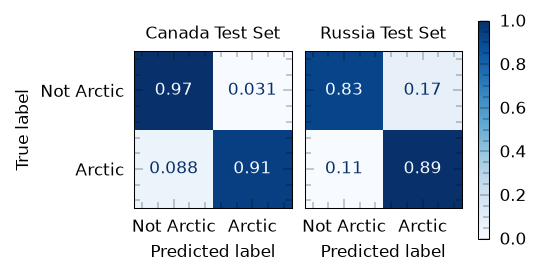

In [76]:
fig, ax = plt.subplots(1, 2, figsize=(3.5, 1.75), sharey=True, layout="constrained", dpi=150)
ConfusionMatrixDisplay.from_estimator(
    bin_class, X_canada_test, y_canada_test, display_labels=['Not Arctic', 'Arctic'], cmap=plt.cm.Blues, normalize='true', ax=ax[0], colorbar=False)
ax[0].set_title("Canada Test Set", fontsize=8)
ConfusionMatrixDisplay.from_estimator(
    bin_class, X_russia_test, y_russia_test, display_labels=['Not Arctic', 'Arctic'], cmap=plt.cm.Blues, normalize='true', ax=ax[1], colorbar=False)
ax[1].set_title("Russia Test Set", fontsize=8)
ax[1].set_ylabel("")
sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.05, pad=0.05)


# save the figure
plt.savefig(FIG_DIR + "bin_class_confusion_matrices.pdf", bbox_inches='tight')

#### 3.4. Feature importance and model interpretation
Analyze which features played the most crucial role in your model's decisions. Finally, discuss and interpret your results comprehensively, and explore any misclassifications to gain
valuable insights into how well machine learning models adapt to different continents and
environments. Are all features that you used for training necessary? Could you reduce the
number of features used? Were there features that you did not use that could be important? Why would they be important?

Optional: Plot the misclassified regions on a world map.

In [56]:
feature_imp = pd.DataFrame(
    {'importance':bin_class.feature_importances_},
    index=X_train.columns)
feature_imp = feature_imp.sort_values(by='importance', ascending=False)
print("\nFeature Importances:")
for i, (feature, row) in enumerate(feature_imp.iterrows()):
    print(f"{i+1}. {feature}: {row['importance']:.6f}")


Feature Importances:
1. FallMean_tmp: 0.113903
2. FallMean_tmax: 0.090455
3. SummerMean_tmax: 0.070103
4. SummerMean_tmin: 0.067856
5. SpringStd_tmin: 0.064316
6. FallMean_tmin: 0.057715
7. SummerMean_tswrf: 0.050612
8. SpringStd_tmp: 0.050046
9. FallMean_tswrf: 0.045290
10. SummerMean_tmp: 0.043996
11. WinterMean_tmax: 0.033035
12. WinterMean_tmin: 0.030862
13. SpringStd_tmax: 0.026866
14. SpringMean_tmax: 0.021776
15. SpringMean_tmp: 0.021417
16. SpringMean_tmin: 0.019404
17. WinterMean_tmp: 0.018108
18. WinterStd_tswrf: 0.015250
19. WinterStd_tmp: 0.012625
20. SummerStd_pre: 0.011819
21. SpringMean_tswrf: 0.011763
22. SummerStd_tmp: 0.011750
23. WinterMean_tswrf: 0.011656
24. SummerStd_tmax: 0.011305
25. FallStd_tmax: 0.010753
26. SummerStd_tmin: 0.010157
27. SpringMean_pre: 0.007802
28. WinterStd_tmax: 0.006429
29. FallStd_tmp: 0.006388
30. FallStd_tmin: 0.005917
31. WinterStd_pre: 0.005087
32. SummerMean_pre: 0.004834
33. WinterStd_tmin: 0.004349
34. WinterMean_pre: 0.004148
35. 

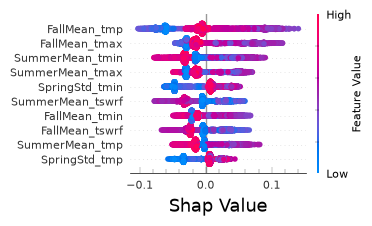

In [57]:
explainer = shap.TreeExplainer(bin_class)
shap_values = explainer.shap_values(X_train.to_pandas())
shap.summary_plot(shap_values[:,:,1], X_train.to_pandas(), show=False, max_display=10)

plt.gcf().set_size_inches(3, 1.85)

plt.gca().set_xlabel('Shap Value')
plt.gca().tick_params(axis='both', which='major', labelsize=8)

cbar = plt.gcf().axes[-1]
cbar.set_ylabel('Feature Value', fontsize=8)
cbar.tick_params(axis='both', which='major', labelsize=8)

for collection in plt.gca().collections:
    collection.set_rasterized(True)

plt.savefig(FIG_DIR + "bin_class_shap_summary.pdf", bbox_inches='tight')
plt.show()

#### Geographical Plots

In [58]:
fig_size = (10, 1.7)
marker_size = 0.25
dpi = 150

In [59]:
proj_canada = ccrs.Mercator(central_longitude=canada_df.select(pl.col("Lon")).mean().item())
proj_russia = ccrs.Mercator(central_longitude=russia_df.select(pl.col("Lon")).mean().item())

present_biomes_canada = canada_df.select("Biome_obs_lpj").unique().sort("Biome_obs_lpj").to_series().to_list()
present_biomes_russia = russia_df.select("Biome_obs_lpj").unique().sort("Biome_obs_lpj").to_series().to_list()
present_biomes_union = list(set(present_biomes_canada) | set(present_biomes_russia))

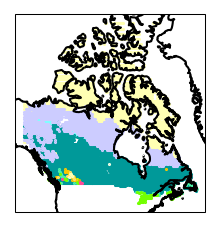

In [60]:
fig, ax = plt.subplots(figsize=fig_size, dpi=dpi, subplot_kw={"projection": proj_canada})

for biome_id in present_biomes_canada:
    i = biome_id - 1
    name = biome_names[i]
    biome = canada_df.filter(pl.col("Biome_obs_lpj") == biome_id)
    ax.scatter(
        biome["Lon"].to_numpy(), 
        biome["Lat"].to_numpy(), 
        color=biome_rgbs[i],
        s=marker_size, 
        transform=proj
        )
ax.coastlines()

for collection in ax.collections:
    collection.set_rasterized(True)

plt.savefig(FIG_DIR + "biome_distribution_canada.pdf", bbox_inches='tight')
plt.show()

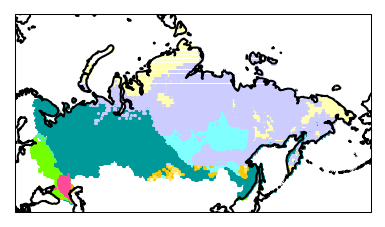

In [61]:
fig, ax = plt.subplots(figsize=fig_size, dpi=dpi, subplot_kw={"projection": proj_russia})

for biome_id in present_biomes_russia:
    i = biome_id - 1
    name = biome_names[i]
    biome = russia_df.filter(pl.col("Biome_obs_lpj") == biome_id)
    ax.scatter(
        biome["Lon"].to_numpy(), 
        biome["Lat"].to_numpy(), 
        color=biome_rgbs[i],
        s=marker_size, 
        transform=proj
        )
ax.coastlines()

for collection in ax.collections:
    collection.set_rasterized(True)

plt.savefig(FIG_DIR + "biome_distribution_russia.pdf", bbox_inches='tight')
plt.show()

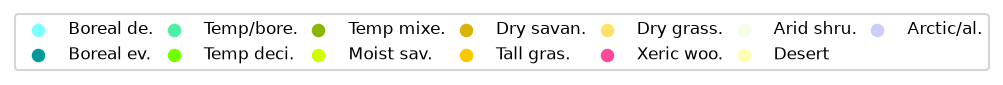

In [67]:
fig, ax = plt.subplots(figsize=(0.1,0.1), dpi=dpi)
for biome_id in present_biomes_union:
    i = biome_id - 1
    name = biome_names[i]
    if len(name) > 9:
        name = name[:9] + "."
    ax.scatter([], [], color=biome_rgbs[i], label=name, s=30)
ax.axis('off')
legend = ax.legend(loc="center", ncols=7, columnspacing=0.25)
plt.savefig(FIG_DIR + "biome_distribution_legend.pdf", bbox_inches='tight')
plt.show()

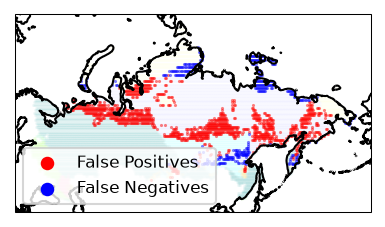

In [68]:
fig, ax = plt.subplots(figsize=fig_size, dpi=dpi, subplot_kw={"projection": proj_russia})

for biome_id in present_biomes_russia:
    i = biome_id - 1
    name = biome_names[i]
    biome = russia_df.filter(pl.col("Biome_obs_lpj") == biome_id)
    ax.scatter(
        biome["Lon"].to_numpy(), 
        biome["Lat"].to_numpy(), 
        color=biome_rgbs[i],
        s=marker_size, 
        alpha=0.05,
        transform=proj
        )

y_pred = bin_class.predict(X_russia_test)
fp = (y_pred == 1) & (y_russia_test == 0)
fn = (y_pred == 0) & (y_russia_test == 1)
fp_df = russia_df.filter(fp)
fn_df = russia_df.filter(fn)

ax.scatter(fp_df["Lon"].to_numpy(), fp_df["Lat"].to_numpy(), color="red", 
s=marker_size, alpha=0.5, transform=proj)
ax.scatter(fn_df["Lon"].to_numpy(), fn_df["Lat"].to_numpy(), color="blue", 
s=marker_size, alpha=0.5, transform=proj)

ax.coastlines()

for collection in ax.collections:
    collection.set_rasterized(True)

# manually create a legend for the false positives and false negatives
ax.scatter([], [], color="red", label="False Positives", s=30)
ax.scatter([], [], color="blue", label="False Negatives", s=30)
ax.legend(loc="lower left", fontsize=8)

plt.savefig(FIG_DIR + "bin_class_russia_fp_fn.pdf", bbox_inches='tight')
plt.show()

# 4. Multiclass classification
In this part, you are going to build two multiclass random forest classification models to
classify up to 18 biomes. You can use a combination of country code and region to build a
subset that you as a group would be interested in, e.g. South America, Europe, South-east
Asia et.c., again try to find another region where an interesting comparison can be made
and if your model are performing well on a different geographic region. For example boreal
Europe vs Canada, mainland USA (not including Alaska) vs. Australia or South America
vs. Africa. Important: Use “Biome_obs” as your target variable.

In [86]:
east_df = merged_df.filter(pl.col("Lon") >= 0)
X_east = drop_ground_truth(east_df)
y_east = east_df.select(pl.col("Biome_obs_lpj").cast(pl.Int32)).to_numpy().flatten()

west_df = merged_df.filter(pl.col("Lon") < 0)
X_west = drop_ground_truth(west_df)
y_west = west_df.select(pl.col("Biome_obs_lpj").cast(pl.Int32)).to_numpy().flatten()

#### 4.1 Data split
Split your dataset into two parts: a training set, and a test set. The training set is used to
train the model, the validation set to tune hyperparameters, and the test set to evaluate
model performance.

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X_east, y_east, test_size=0.2, random_state=RANDOM_SEED, stratify=y_east)

#### 4.2 Model training
Next, train a Random Forest classification model using training data, and then put the
model on the test data.

In [88]:
# Train a baseline model with default hyperparameters
multi_class = RandomForestClassifier(random_state=RANDOM_SEED)
multi_class.fit(X_train, y_train)

/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:160: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:175: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:160: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(
/home/hugowall/work/courses/BERN01/biome_project/.venv/lib64/python3.14/site-packages/sklearnex/_utils.py:175: UserWarning: Hyperparameters are static variables and can not be modified per instance.
  warnings.warn(


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [89]:
print("\nClassification Report (east):")
target_names = [biome_names[i-1] for i in set(y_test)]
print(classification_report(y_test, multi_class.predict(X_test), target_names=target_names, zero_division=0))

print("\nClassification Report (west):")
target_names = [biome_names[i-1] for i in set(y_west)]
print(classification_report(y_west, multi_class.predict(X_west), target_names=target_names, zero_division=0))


Classification Report (east):
                      precision    recall  f1-score   support

 Boreal decid forest       0.92      0.90      0.91       268
  Boreal ever forest       0.95      0.97      0.96      1200
 Temp/boreal mix fo.       0.79      0.54      0.64        91
   Temp decid forest       0.89      0.95      0.92       479
 Temp broad ever fo.       0.93      0.95      0.94       275
   Temp mixed forest       0.00      0.00      0.00        11
  Trop season forest       0.68      0.70      0.69       283
    Trop rain forest       0.92      0.93      0.93       513
   Trop decid forest       0.71      0.73      0.72       213
      Moist savannas       0.80      0.66      0.72        87
        Dry savannas       0.79      0.84      0.81       336
      Tall grassland       0.68      0.45      0.54        42
       Dry grassland       0.77      0.72      0.75       366
    Xeric wood/shrub       0.77      0.69      0.73       245
   Arid shrub/steppe       0.84      0

## 4.3 Hyper-parameter Tuning
Use cross-validation to tune hyperparameters like the number of trees, tree depth, and
minimum leaf samples. This step can help improve model performance. If you encounter
issues with runtime, consider narrowing your focus to fewer geographic regions. It is also
possible to sample the grid list with the .sample() function on Pandas DataFrames, in that
case, make sure to sample only the training dataset and not the full dataset.

In [93]:
# Define parameters to test in the grid search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4],
}

# Train a multi-class model with hyperparameter tuning using grid search
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
rfc = RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)

grid_search = HalvingGridSearchCV(estimator=rfc, param_grid=param_grid, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)
multi_class_tuned = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print(f"Best CV accuracy: {grid_search.best_score_:.4f}")

n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 934
max_resources_: 25225
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 36
n_resources: 934
Fitting 5 folds for each of 36 candidates, totalling 180 fits
----------
iter: 1
n_candidates: 12
n_resources: 2802
Fitting 5 folds for each of 12 candidates, totalling 60 fits
----------
iter: 2
n_candidates: 4
n_resources: 8406
Fitting 5 folds for each of 4 candidates, totalling 20 fits
----------
iter: 3
n_candidates: 2
n_resources: 25218
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV accuracy: 0.7764


## 4.4. Model Evaluation
Evaluate the model's performance using appropriate metrics for multiclass classification.



In [94]:
print("\nClassification Report (east):")
target_names = [biome_names[i-1] for i in set(y_test)]
print(classification_report(y_test, multi_class_tuned.predict(X_test), target_names=target_names, zero_division=0))

print("\nClassification Report (west):")
target_names = [biome_names[i-1] for i in set(y_west)]
print(classification_report(y_west, multi_class_tuned.predict(X_west), target_names=target_names, zero_division=0))


Classification Report (east):
                      precision    recall  f1-score   support

 Boreal decid forest       0.93      0.90      0.92       268
  Boreal ever forest       0.95      0.97      0.96      1200
 Temp/boreal mix fo.       0.81      0.56      0.66        91
   Temp decid forest       0.89      0.95      0.92       479
 Temp broad ever fo.       0.92      0.96      0.94       275
   Temp mixed forest       0.00      0.00      0.00        11
  Trop season forest       0.68      0.72      0.70       283
    Trop rain forest       0.92      0.93      0.93       513
   Trop decid forest       0.73      0.73      0.73       213
      Moist savannas       0.81      0.67      0.73        87
        Dry savannas       0.80      0.84      0.82       336
      Tall grassland       0.79      0.52      0.63        42
       Dry grassland       0.80      0.73      0.76       366
    Xeric wood/shrub       0.78      0.69      0.73       245
   Arid shrub/steppe       0.84      0

In [95]:

metrics_multi = [] #list to save the values

#evaluate both the baseline and tuned models on the test set and save the metrics
for name, model in {"Baseline": multi_class, "Tuned": multi_class_tuned}.items(): 
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    metrics_multi.append({"model": name,
                        "accuracy": accuracy_score(y_test, y_pred),
                        "balanced accuracy":balanced_accuracy_score(y_test, y_pred),
                        "macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
                        "cross entropy": log_loss(y_test, y_prob, labels=model.classes_),
                        "Cohen's kappa": cohen_kappa_score(y_test, y_pred)})

display(pd.DataFrame(metrics_multi).set_index("model"))

,accuracy,balanced accuracy,macro F1,cross entropy,Cohen's kappa
model,,,,,
Baseline,0.879340,0.751221,0.763981,0.398293,0.866489
Tuned,0.884097,0.760920,0.774651,0.345589,0.871741


In [96]:

metrics_multi = [] #list to save the values

#evaluate both the baseline and tuned models on the test set and save the metrics
for name, model in {"Baseline": multi_class, "Tuned": multi_class_tuned}.items(): 
    y_pred = model.predict(X_west)
    y_prob = model.predict_proba(X_west)
    metrics_multi.append({"model": name,
                        "accuracy": accuracy_score(y_west, y_pred),
                        "balanced accuracy":balanced_accuracy_score(y_west, y_pred),
                        "macro F1": f1_score(y_west, y_pred, average="macro", zero_division=0),
                        "cross entropy": log_loss(y_west, y_prob, labels=model.classes_),
                        "Cohen's kappa": cohen_kappa_score(y_west, y_pred)})

display(pd.DataFrame(metrics_multi).set_index("model"))

,accuracy,balanced accuracy,macro F1,cross entropy,Cohen's kappa
model,,,,,
Baseline,0.704524,0.500717,0.466913,0.981673,0.668978
Tuned,0.704524,0.499833,0.467828,0.939704,0.669018


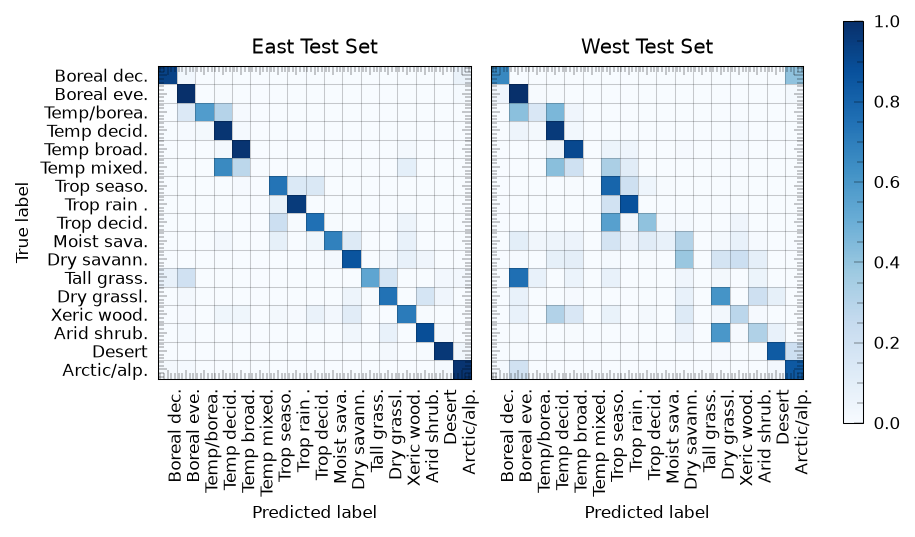

In [125]:
# plot confusion matrices for tuned model on east and west test sets
fig, ax = plt.subplots(1, 2, figsize=(6, 3.5), sharey=True, layout="constrained", dpi=150)

target_names_east = [biome_names[i-1] for i in set(y_test)]
target_names_west = [biome_names[i-1] for i in set(y_west)]
assert target_names_east == target_names_west, "Target names for east and west test sets do not match."

target_names = target_names_east  # Use the same target names for both confusion matrices

# shorten target names if they are too long
target_names = [name if len(name) <= 10 else name[:10] + "." for name in target_names]

ConfusionMatrixDisplay.from_estimator(
    multi_class_tuned, X_test, y_test, display_labels=target_names, cmap=plt.cm.Blues, normalize='true', ax=ax[0], colorbar=False, include_values=False)

ConfusionMatrixDisplay.from_estimator(
    multi_class_tuned, X_west, y_west, display_labels=target_names, cmap=plt.cm.Blues, normalize='true', ax=ax[1], colorbar=False, include_values=False)

sm = plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.05, pad=0.05)

ax[1].set_ylabel("")
for axis in ax:
    axis.set_xticklabels(target_names, rotation=90, ha="right", rotation_mode="anchor");

# add horizontal and vertical lines to separate the cells in the confusion matrices
for axis in ax:
    for i in range(len(target_names)):
        axis.axhline(i - 0.5, color='black', linewidth=0.5, alpha=0.2)
        axis.axvline(i - 0.5, color='black', linewidth=0.5, alpha=0.2)

ax[0].set_title("East Test Set");
ax[1].set_title("West Test Set");

plt.savefig(FIG_DIR + "multi_class_confusion_matrices.pdf", bbox_inches='tight')
plt.show()

## 4.5. Features Importance
Analyze which features played the most crucial role in your model's decisions. What happens when you are limiting the number of features? Also, are there any auto-correlations
in the feature data?

In [126]:
feature_imp = pd.DataFrame(
    {'importance':multi_class_tuned.feature_importances_},
    index=X_train.columns)
feature_imp = feature_imp.sort_values(by='importance', ascending=False)
print("\nFeature Importances:")
for i, (feature, row) in enumerate(feature_imp.iterrows()):
    print(f"{i+1}. {feature}: {row['importance']:.6f}")


Feature Importances:
1. SpringMean_tmp: 0.046990
2. WinterMean_tmp: 0.043534
3. SpringMean_tmin: 0.042932
4. SummerMean_pre: 0.042374
5. WinterMean_tmax: 0.041271
6. SpringMean_tmax: 0.037985
7. WinterMean_pre: 0.036661
8. WinterMean_tmin: 0.035755
9. FallMean_tmp: 0.035138
10. SummerStd_tmp: 0.033016
11. SummerMean_tmp: 0.031404
12. FallMean_tmax: 0.028099
13. SummerStd_tmin: 0.027930
14. FallMean_tmin: 0.026037
15. WinterStd_tmp: 0.025946
16. WinterStd_pre: 0.025881
17. FallMean_pre: 0.025833
18. SummerMean_tmax: 0.023460
19. SummerMean_tmin: 0.023134
20. SummerStd_pre: 0.022577
21. SpringMean_tswrf: 0.022300
22. WinterMean_tswrf: 0.021635
23. SummerStd_tmax: 0.021632
24. WinterStd_tmin: 0.019463
25. FallStd_pre: 0.017871
26. FallMean_tswrf: 0.017715
27. SpringStd_tmp: 0.017444
28. SpringMean_pre: 0.017285
29. SpringStd_tmax: 0.016259
30. WinterStd_tmax: 0.015673
31. FallStd_tmp: 0.015041
32. SummerMean_tswrf: 0.014648
33. FallStd_tmax: 0.014105
34. SpringStd_pre: 0.012377
35. Summe

In [139]:
# SHAP analysis for the tuned multi-class model
sample = X_train.to_pandas().sample(50, random_state=RANDOM_SEED)  # subsample for speed
explainer = shap.TreeExplainer(multi_class_tuned)
sv = explainer.shap_values(sample)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv

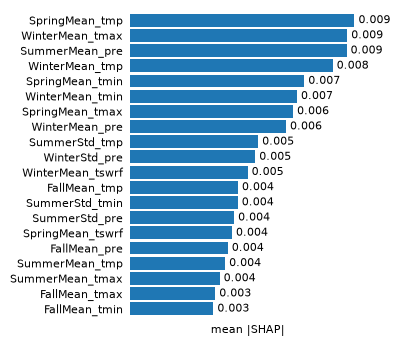

In [140]:
importance = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=sample.columns).sort_values().tail(20)
fig, ax = plt.subplots(figsize=(4, 3.5))
importance.plot.barh(ax=ax, width=0.85)
ax.set_xlabel("mean |SHAP|"); ax.set_ylabel(""); ax.set_title("")
ax.set_xticks([]); ax.set_yticks(range(len(importance)), importance.index) 
ax.tick_params(axis="y", which="both", length=0)

for spine in ax.spines.values(): 
   spine.set_visible(False)

for i, value in enumerate(importance): 
   ax.text(value, i, f" {value:.3f}", va="center")

plt.tight_layout(); plt.show()

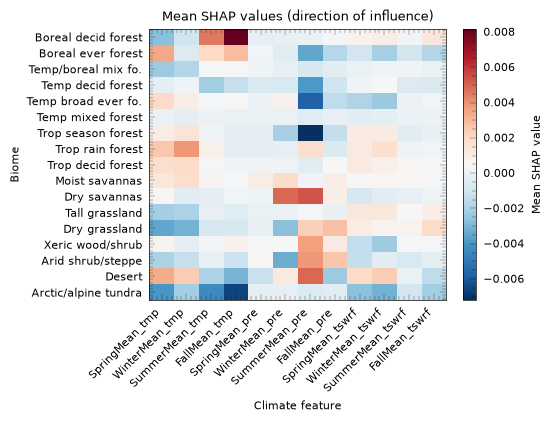

In [141]:
selected_features = ["SpringMean_tmp", "WinterMean_tmp", "SummerMean_tmp", "FallMean_tmp", 
                      "SpringMean_pre", "WinterMean_pre", "SummerMean_pre", "FallMean_pre", 
                      "SpringMean_tswrf", "WinterMean_tswrf", "SummerMean_tswrf", "FallMean_tswrf"]

# Plot the direction of influence for the selected features
mean_shap = sv.mean(axis=0)
shap_direction = pd.DataFrame(mean_shap.T, index=multi_class_tuned.classes_, columns=sample.columns)
shap_direction.index = [
    biome_names[i - 1]
    for i in multi_class_tuned.classes_]
fig, ax = plt.subplots(figsize=(4, 3.5))

# plot heatmap using plt
im = ax.imshow(shap_direction[selected_features], cmap="RdBu_r", aspect="auto")
ax.set_xticks(range(len(selected_features)))
ax.set_xticklabels(selected_features, rotation=45, ha="right")
ax.set_yticks(range(len(shap_direction.index)))
ax.set_yticklabels(shap_direction.index)
ax.set_xlabel("Climate feature")
ax.set_ylabel("Biome")
ax.set_title("Mean SHAP values (direction of influence)")
# add colorbar
cbar = plt.colorbar(im, ax=ax, orientation='vertical', fraction=0.05, pad=0.05)
cbar.set_label("Mean SHAP value")

For a particular feature:
- SHAP = 0 → essentially no contribution to that observation's prediction.
- SHAP > 0 → the feature pushes the model toward that biome.
- SHAP < 0 → the feature pushes the model away from that biome.
- Further from 0 → stronger influence.

## 4.6. Compare LPJ-GUESS model and machine learning model
Compare your trained against the biomes estimated by LPJ-GUESS for “Biome_Cmax”
and Biome_LAI. Discuss the difference in prediction between the LPJ-GUESS outputs and
the machine learning model outputs. Where do the models agree and where do the model
predictions diverge? Why?

In [99]:
# Split the data into training and testing sets to get the test_df for LPJ-GUESS predictions
_, idx_test = train_test_split(np.arange(len(y_east)), test_size=0.2, random_state=RANDOM_SEED, stratify=y_east)
# reindex east_df
test_df = east_df[idx_test]

# Collect the oberved values and predictions from both models
obs = y_test
preds = {"Random Forest": multi_class_tuned.predict(X_test),
        "LPJ Cmax": test_df["Biome_Cmax_lpj"].cast(pl.Int32).to_numpy(),
        "LPJ Lai": test_df["Biome_LAI_lpj"].cast(pl.Int32).to_numpy()}

# Evaluate the models and store the metrics in a list of dictionaries
metrics_comp = []
for name, p in preds.items():
    metrics_comp.append({"model": name,
                        "accuracy": accuracy_score(obs, p),
                        "macro F1": f1_score(obs, p, average="macro", labels=np.unique(obs)),
                        "Cohen's kappa": cohen_kappa_score(obs, p)})
display(pd.DataFrame(metrics_comp).set_index("model"))

,accuracy,macro F1,Cohen's kappa
model,,,
Random Forest,0.884097,0.774651,0.871741
LPJ Cmax,0.169494,0.110309,0.136911
LPJ Lai,0.163945,0.124693,0.134043


#### Geographical Plots

/tmp/ipykernel_7374/1002911176.py:2: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.05, hspace=0.05)


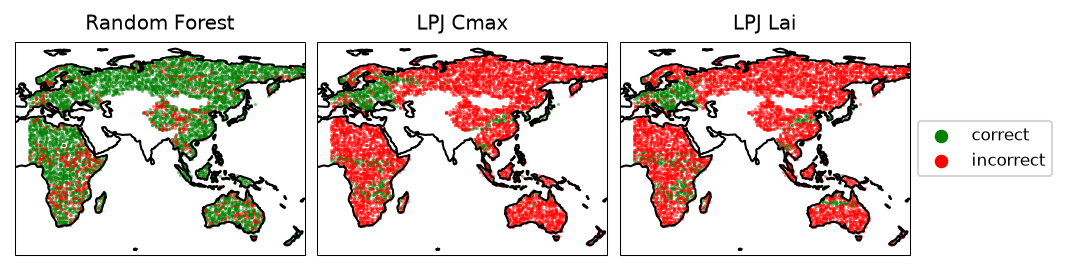

In [100]:
fig, ax = plt.subplots(1, 3, figsize=(7, 3), subplot_kw=dict(projection=proj), dpi=150, layout="constrained")
plt.subplots_adjust(wspace=0.05, hspace=0.05)

for i, (name, p) in enumerate(preds.items()):
    cats = {"correct": ("green", obs == p), "incorrect": ("red", obs != p)}
    lon, lat = test_df.select(pl.col("Lon"), pl.col("Lat")).to_numpy().T
    for cat, (color, mask) in cats.items():
        ax[i].scatter(lon[mask], lat[mask], color=color, s=marker_size, alpha=0.5, transform=proj)

    ax[i].set_title(name)
    ax[i].coastlines()

    for collection in ax[i].collections:
        collection.set_rasterized(True)

ax[2].scatter([], [], color="green", label="correct", s=30)
ax[2].scatter([], [], color="red", label="incorrect", s=30)
ax[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))

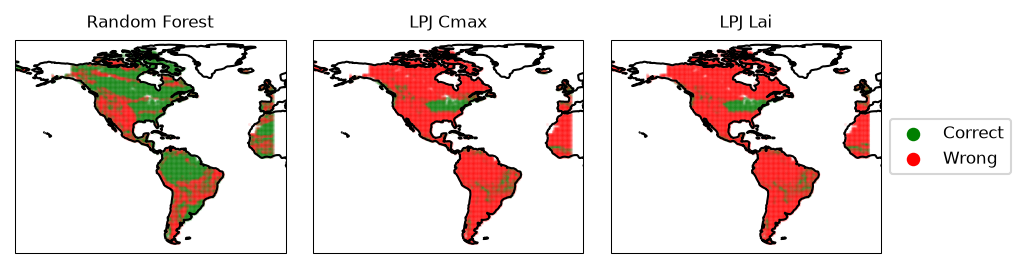

In [101]:
preds = {"Random Forest": multi_class_tuned.predict(X_west),
        "LPJ Cmax": west_df["Biome_Cmax_lpj"].cast(pl.Int32).to_numpy(),
        "LPJ Lai": west_df["Biome_LAI_lpj"].cast(pl.Int32).to_numpy()}

# plot 3 maps of west showing where each model is correct or wrong
fig, ax = plt.subplots(1, 3, figsize=(7, 3), subplot_kw=dict(projection=proj), dpi=150)
# decrease the space between subplots
plt.subplots_adjust(wspace=0.1, hspace=0.01)

for i, (name, p) in enumerate(preds.items()):
    cats = {"Correct": ("green", (p==y_west)),
            "Wrong": ("red", (p!=y_west))}

    lon, lat = west_df["Lon"].to_numpy(), west_df["Lat"].to_numpy()
    for label, (color, m) in cats.items():
        ax[i].scatter(lon[m], lat[m], s=0.25, alpha=0.1, color=color, transform=proj)
    ax[i].coastlines()
    ax[i].set_title(name, fontsize=8)

    # enable rasterization for all scatter plots in the current axis
    for collection in ax[i].collections:
        collection.set_rasterized(True)

ax[2].scatter([], [], color="green", label="Correct", s=30)
ax[2].scatter([], [], color="red", label="Wrong", s=30)
ax[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))

# 5. Regression

In this part, you are going to build two random forest regression models to predict two continuous variables. One model to predict “NPP” and another to predict “VegC”. Split the data similar to section 4.1. and train your regression models on the training data.

In [35]:
# Splitting the data into train and test sets for regression models as in 4.1
X_reg = drop_ground_truth(merged_df)
y_npp = merged_df["NPP_lpj"].to_numpy()
y_vegC = merged_df["VegC_lpj"].to_numpy()

npp_scale = y_npp.max() - y_npp.min()
vegC_scale = y_vegC.max() - y_vegC.min()

# Splitting the data into train and test sets for east_df, but we don't need to stratify the data, as NPP and VegC are continuous variables
X_reg_train, X_reg_test, y_npp_train, y_npp_test, y_vegC_train, y_vegC_test = train_test_split(
    X_reg, y_npp, y_vegC, test_size=0.2, random_state=RANDOM_SEED)

In [14]:
# Train a Random Forest Regressor for NPP and VegC
model_reg_NPP = RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1)
model_reg_NPP.fit(X_reg_train, y_npp_train)

model_reg_VegC = RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1)
model_reg_VegC.fit(X_reg_train, y_vegC_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 5.1 Model Evaluation

Evaluate the model's performance using appropriate metrics for regression, such as mean
squared error.

In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Evaluate the regression models and save the metrics
targets = [("NPP", model_reg_NPP, y_npp_train, y_npp_test), 
           ("VegC", model_reg_VegC, y_vegC_train, y_vegC_test)]

reg_comp = [] # List to save the values

# Evaluate both the NPP and VegC regression models on the test set and save the metrics
for name, model, ytr, yte in targets:
    y_pred = model.predict(X_reg_test)
    rmse = np.sqrt(mean_squared_error(yte, y_pred))
    reg_comp.append({"model": name,
                    "MSE": mean_squared_error(yte, y_pred),
                    "MAE": mean_absolute_error(yte, y_pred),
                    "train R2": r2_score(ytr, model.predict(X_reg_train)),
                    "test R2": r2_score(yte, y_pred),
                    "RMSE": rmse,
                    "NRMSE": rmse / (yte.max() - yte.min())}) #Q: Should we add cross entropy and Cohen's kappa for regression models? A: No, those metrics are not applicable to regression models.

display(pd.DataFrame(reg_comp).set_index("model"))

,MSE,MAE,train R2,test R2,RMSE,NRMSE
model,,,,,,
NPP,0.002115,0.024500,0.996612,0.978913,0.045987,0.028283
VegC,2.985848,0.875869,0.987069,0.918567,1.727961,0.043837


In [37]:
# Evaluate the regression models per biome on the test set
_, idx_test = train_test_split(np.arange(len(merged_df)), test_size=0.2, random_state=RANDOM_SEED)
biome_test = merged_df["Biome_obs_lpj"].to_numpy()[idx_test]

# Evaluate both the NPP and VegC regression models on the test set and save the metrics per biome
for name, model, ytr, yte in targets:
    y_pred = model.predict(X_reg_test)
    df = pd.DataFrame({"biome": biome_test, "obs": yte, "pred": y_pred})
    df["abs_err"] = np.abs(df["pred"] - df["obs"])
    df["sq_err"] = (df["pred"] - df["obs"])**2
    df_out = df.groupby("biome").agg(n=("obs", "size"),
                                     mean_obs=("obs", "mean"),
                                     mean_pred=("pred", "mean"),
                                     MAE = ("abs_err", "mean"),
                                     MSE = ("sq_err", "mean"))

    df_out["RMSE"] = np.sqrt(df_out.pop("MSE"))
    df_out["NRMSE"] = df_out["RMSE"] / (df_out["mean_obs"].max() - df_out["mean_obs"].min())
    df_out.index = [biome_names[i-1] for i in df_out.index]
    print(f"\n{name}: errors per biome on the test set")
    display(df_out)


NPP: errors per biome on the test set


,n,mean_obs,mean_pred,MAE,RMSE,NRMSE
Boreal decid forest,261,0.451862,0.451405,0.011228,0.016177,0.015762
Boreal ever forest,1909,0.521215,0.512101,0.023542,0.042812,0.041715
Temp/boreal mix fo.,143,0.608007,0.591830,0.029311,0.044330,0.043193
Temp decid forest,761,0.486883,0.490030,0.016594,0.022449,0.021874
Temp broad ever fo.,536,0.462935,0.477040,0.028825,0.068719,0.066957
Temp mixed forest,23,0.550000,0.559529,0.061499,0.120166,0.117086
Trop season forest,473,0.814772,0.807168,0.038253,0.059529,0.058003
Trop rain forest,1168,1.030136,1.025577,0.043769,0.060910,0.059349
Trop decid forest,328,0.699747,0.691057,0.028565,0.040763,0.039718
Moist savannas,147,0.502163,0.504337,0.037430,0.064428,0.062777



VegC: errors per biome on the test set


,n,mean_obs,mean_pred,MAE,RMSE,NRMSE
Boreal decid forest,261,2.380050,2.423602,0.417268,0.563988,0.030699
Boreal ever forest,1909,5.079892,4.949090,0.867311,1.251793,0.068138
Temp/boreal mix fo.,143,8.000399,7.967562,1.293255,1.704250,0.092767
Temp decid forest,761,6.946403,6.828377,0.835196,1.058645,0.057625
Temp broad ever fo.,536,5.194228,5.544811,0.842878,1.980506,0.107804
Temp mixed forest,23,6.065609,7.370400,1.700381,2.758061,0.150128
Trop season forest,473,10.159319,10.838600,1.989875,2.637919,0.143589
Trop rain forest,1168,18.384687,18.002339,2.964615,3.921988,0.213484
Trop decid forest,328,8.271345,8.538033,1.224132,1.587804,0.086428
Moist savannas,147,3.295088,3.866710,0.996757,1.592221,0.086669


## 5.2 Feature Importance

In [25]:
# Print feature importances for the NPP regression model
feature_imp_NPP = pd.DataFrame(
    {'importance':model_reg_NPP.feature_importances_},
    index=X_reg_train.columns)
feature_imp_NPP = feature_imp_NPP.sort_values(by='importance', ascending=False) 

print("\nFeature Importances (NPP model):")
print(feature_imp_NPP.head(60))


Feature Importances (NPP model):
                   importance
WinterMean_pre       0.348006
SummerMean_pre       0.234659
SummerStd_tmp        0.118079
WinterStd_tmp        0.056985
SummerStd_pre        0.034114
SummerMean_tmin      0.031829
FallMean_pre         0.022750
SummerMean_tmp       0.021793
FallMean_tmp         0.018262
SpringMean_pre       0.013080
SummerMean_tmax      0.009953
WinterStd_pre        0.008171
SummerMean_tswrf     0.006753
SpringMean_tswrf     0.006527
WinterMean_tswrf     0.005854
pH_soil              0.005691
SpringMean_tmp       0.005214
FallStd_pre          0.003932
FallMean_tswrf       0.003895
FallMean_tmax        0.003437
WinterMean_tmp       0.003157
WinterMean_tmax      0.002720
WinterStd_tswrf      0.002426
SpringStd_tmp        0.002372
SpringMean_tmax      0.002369
SummerStd_tmin       0.002310
WinterMean_tmin      0.002108
FallStd_tmp          0.001914
SummerStd_tswrf      0.001848
SpringMean_tmin      0.001774
SummerStd_tmax       0.001658
Spring

In [24]:
# Print feature importances for the VegC regression model
feature_imp_VegC = pd.DataFrame(
    {'importance':model_reg_VegC.feature_importances_},
    index=X_reg_train.columns)
feature_imp_VegC = feature_imp_VegC.sort_values(by='importance', ascending=False) 

print("\nFeature Importances (VegC model):")
print(feature_imp_VegC.head(60))


Feature Importances (VegC model):
                   importance
WinterMean_pre       0.498859
SummerMean_pre       0.168666
FallStd_tmp          0.079782
SummerMean_tmin      0.024730
FallMean_pre         0.022267
SpringMean_tmp       0.020635
SpringMean_pre       0.017217
WinterStd_tmp        0.012827
SummerStd_tmp        0.011485
SummerMean_tmp       0.010464
SummerMean_tmax      0.007712
WinterStd_pre        0.006833
SummerStd_tswrf      0.006804
FallStd_pre          0.006779
SummerMean_tswrf     0.005894
SummerStd_tmin       0.005546
FallMean_tmp         0.005101
WinterMean_tmp       0.004950
SpringMean_tswrf     0.004698
FallMean_tswrf       0.004589
WinterMean_tmax      0.004357
SpringMean_tmax      0.004217
pH_soil              0.003980
SpringStd_tmp        0.003936
WinterMean_tmin      0.003851
WinterStd_tswrf      0.003604
SpringMean_tmin      0.003559
SummerStd_pre        0.003410
WinterStd_tmax       0.003231
SpringStd_tswrf      0.003177
cellfraction_soil    0.003054
FallS

In [17]:
sample = X_reg_test.to_pandas().sample(5, random_state=RANDOM_SEED)

### NPP

In [19]:
sv_npp = shap.TreeExplainer(model_reg_NPP).shap_values(sample)

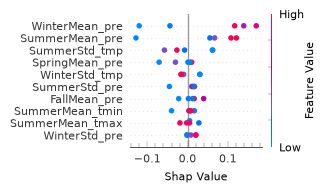

In [46]:
shap.summary_plot(sv_npp, sample, max_display=10, show=False)

plt.gcf().set_size_inches(2.25, 1.55)
plt.gca().set_xlabel('Shap Value', fontsize=8)
plt.gca().tick_params(axis='both', which='major', labelsize=8)

cbar = plt.gcf().axes[-1]
cbar.set_ylabel('Feature Value', fontsize=8)
cbar.tick_params(axis='both', which='major', labelsize=8)

for collection in plt.gca().collections:
    collection.set_rasterized(True)

plt.savefig(FIG_DIR + "npp_shap_summary.pdf", bbox_inches='tight')
plt.show()

### VegC

In [41]:
sv_VegC = shap.TreeExplainer(model_reg_VegC).shap_values(sample)

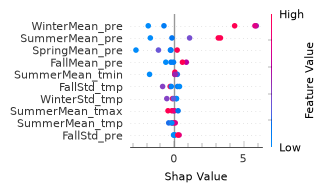

In [47]:
shap.summary_plot(sv_VegC, sample, max_display=10, show=False)

plt.gcf().set_size_inches(2.25, 1.55)
plt.gca().set_xlabel('Shap Value', fontsize=8)
plt.gca().tick_params(axis='both', which='major', labelsize=8)

cbar = plt.gcf().axes[-1]
cbar.set_ylabel('Feature Value', fontsize=8)
cbar.tick_params(axis='both', which='major', labelsize=8)

for collection in plt.gca().collections:
    collection.set_rasterized(True)

plt.savefig(FIG_DIR + "VegC_shap_summary.pdf", bbox_inches='tight')
plt.show()

## 5.3 Compare LPJ GUESS model and machine learning model

Discuss the difference in prediction between the LPJ GUESS model and the machine
learning model. Just as in 4.6, it could be of interest to also analyse the geography of the
performance of the model. An extension would be to use your trained biome-model as input to this model. Will that improve the results? And why? Another way of achieving this would be to create a model for each biome.

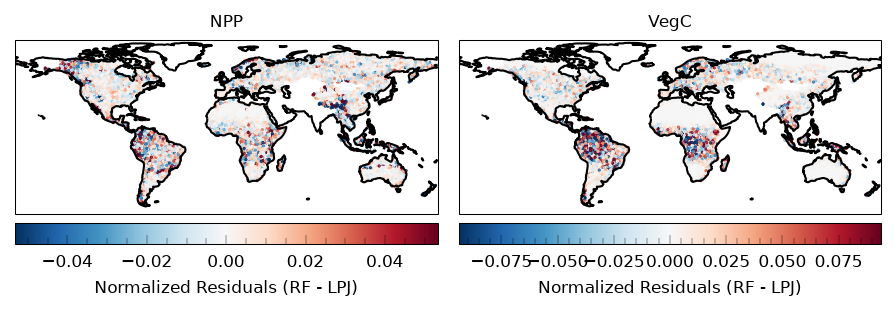

In [49]:
# Get back the test rows with Land and Lon for plotting the residuals on a map
idx_reg_train, idx_reg_test = train_test_split(np.arange(merged_df.height), test_size=0.2, random_state=RANDOM_SEED)
reg_test_df = merged_df[idx_reg_test]
lon, lat = reg_test_df["Lon"].to_numpy(), reg_test_df["Lat"].to_numpy()

# Plot the residuals of the regression models on a map
fig, ax = plt.subplots(1, 2, figsize=(7, 4), subplot_kw=dict(projection=proj), dpi=150)
# decrease the space between subplots
plt.subplots_adjust(wspace=0.05, hspace=0.05)
for ax, (name, model, ytr, yte) in zip(ax, targets):
    higher = model.predict(X_reg_test) - yte # If positive, RF is predicting higher than LPJ
    # rescale the residuals relative to the range of the observed values, so that they are comparable between NPP and VegC
    higher = higher / (yte.max() - yte.min())
    lim = np.quantile(np.abs(higher), 0.95) # Crop the colour values to outliers don't have too much power (visually)
    sc = ax.scatter(lon, lat, c=higher, s=0.25, cmap="RdBu_r", vmin=-lim, vmax=lim, transform=proj)
    ax.coastlines()
    ax.set_title(f"{name}", fontsize=8)
    plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.02, label="Normalized Residuals (RF - LPJ)")

plt.savefig(FIG_DIR + "regression_residuals.pdf", bbox_inches='tight')
plt.show()